In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Membaca dataset
data = pd.read_csv('../content/happiness-classification.csv')
data.head(10)

,infoavail,housecost,schoolquality,policetrust,streetquality,ëvents,happy
0,3,3.0,3,4,2.0,4,0.0
1,3,2.0,3,5,4.0,3,0.0
2,5,3.0,3,3,3.0,5,1.0
3,5,4.0,3,3,3.0,5,0.0
4,5,4.0,3,3,3.0,5,0.0
5,5,5.0,3,5,5.0,5,1.0
6,3,NaN,-95,1235,NaN,3,NaN
7,5,4.0,4,4,4.0,5,1.0
8,4,1.0,4,4,4.0,4,0.0
9,4,NaN,-95,1235,NaN,5,NaN


In [ ]:
data.tail()

,infoavail,housecost,schoolquality,policetrust,streetquality,ëvents,happy
258,3,2.0,3,5,4.0,3,0.0
259,3,3.0,1,3,3.0,4,1.0
260,4,3.0,3,3,3.0,5,0.0
261,5,5.0,3,5,5.0,5,1.0
262,5,4.0,5,5,5.0,5,1.0


# EDA (Exploratory data analysis)


In [ ]:
# Melihat informasi dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   infoavail      263 non-null    int64  
 1   housecost      223 non-null    float64
 2   schoolquality  263 non-null    int64  
 3   policetrust    263 non-null    int64  
 4   streetquality  223 non-null    float64
 5   ëvents         263 non-null    int64  
 6   happy          223 non-null    float64
dtypes: float64(3), int64(4)
memory usage: 14.5 KB


In [ ]:
# Melihat deskripsi statistik dataset
data.describe()

,infoavail,housecost,schoolquality,policetrust,streetquality,ëvents,happy
count,263.000000,223.000000,263.000000,263.000000,223.000000,263.000000,223.000000
mean,4.300380,2.542601,-9.809886,167.619772,3.632287,4.250951,0.533632
std,0.836363,1.064042,33.454908,418.999745,1.114700,0.818296,0.499990
min,1.000000,1.000000,-95.000000,1.000000,1.000000,1.000000,0.000000
25%,4.000000,2.000000,2.000000,3.000000,3.000000,4.000000,0.000000
50%,5.000000,3.000000,3.000000,4.000000,4.000000,4.000000,1.000000
75%,5.000000,3.000000,4.000000,5.000000,4.000000,5.000000,1.000000
max,5.000000,5.000000,5.000000,1235.000000,5.000000,5.000000,1.000000


In [ ]:
data.isna().sum()

infoavail         0
housecost        40
schoolquality     0
policetrust       0
streetquality    40
ëvents            0
happy            40
dtype: int64

In [ ]:
# Melihat jumlah nilai unik pada setiap kolom
data.nunique()

infoavail        4
housecost        5
schoolquality    6
policetrust      6
streetquality    5
ëvents           5
happy            2
dtype: int64

In [ ]:
data.rename(columns={'ëvents': 'events'}, inplace=True)

In [ ]:
# Masukkan nilai yang hilang dengan median untuk 'housecost' dan 'streetquality'
# Untuk 'happy', karena ini adalah hasil kategorikal, kami akan menghilangkan baris dengan nilai yang hilang karena penghitungan dapat membuat hasil menjadi bias.
data['housecost'].fillna(data['housecost'].median(), inplace=True)
data['streetquality'].fillna(data['streetquality'].median(), inplace=True)
data.dropna(subset=['happy'], inplace=True)

data.isnull().sum()

infoavail        0
housecost        0
schoolquality    0
policetrust      0
streetquality    0
events           0
happy            0
dtype: int64

In [ ]:
data.head(10)

,infoavail,housecost,schoolquality,policetrust,streetquality,events,happy
0,3,3.0,3,4,2.0,4,0.0
1,3,2.0,3,5,4.0,3,0.0
2,5,3.0,3,3,3.0,5,1.0
3,5,4.0,3,3,3.0,5,0.0
4,5,4.0,3,3,3.0,5,0.0
5,5,5.0,3,5,5.0,5,1.0
7,5,4.0,4,4,4.0,5,1.0
8,4,1.0,4,4,4.0,4,0.0
10,3,2.0,3,3,2.0,3,0.0
11,4,4.0,3,4,4.0,4,0.0


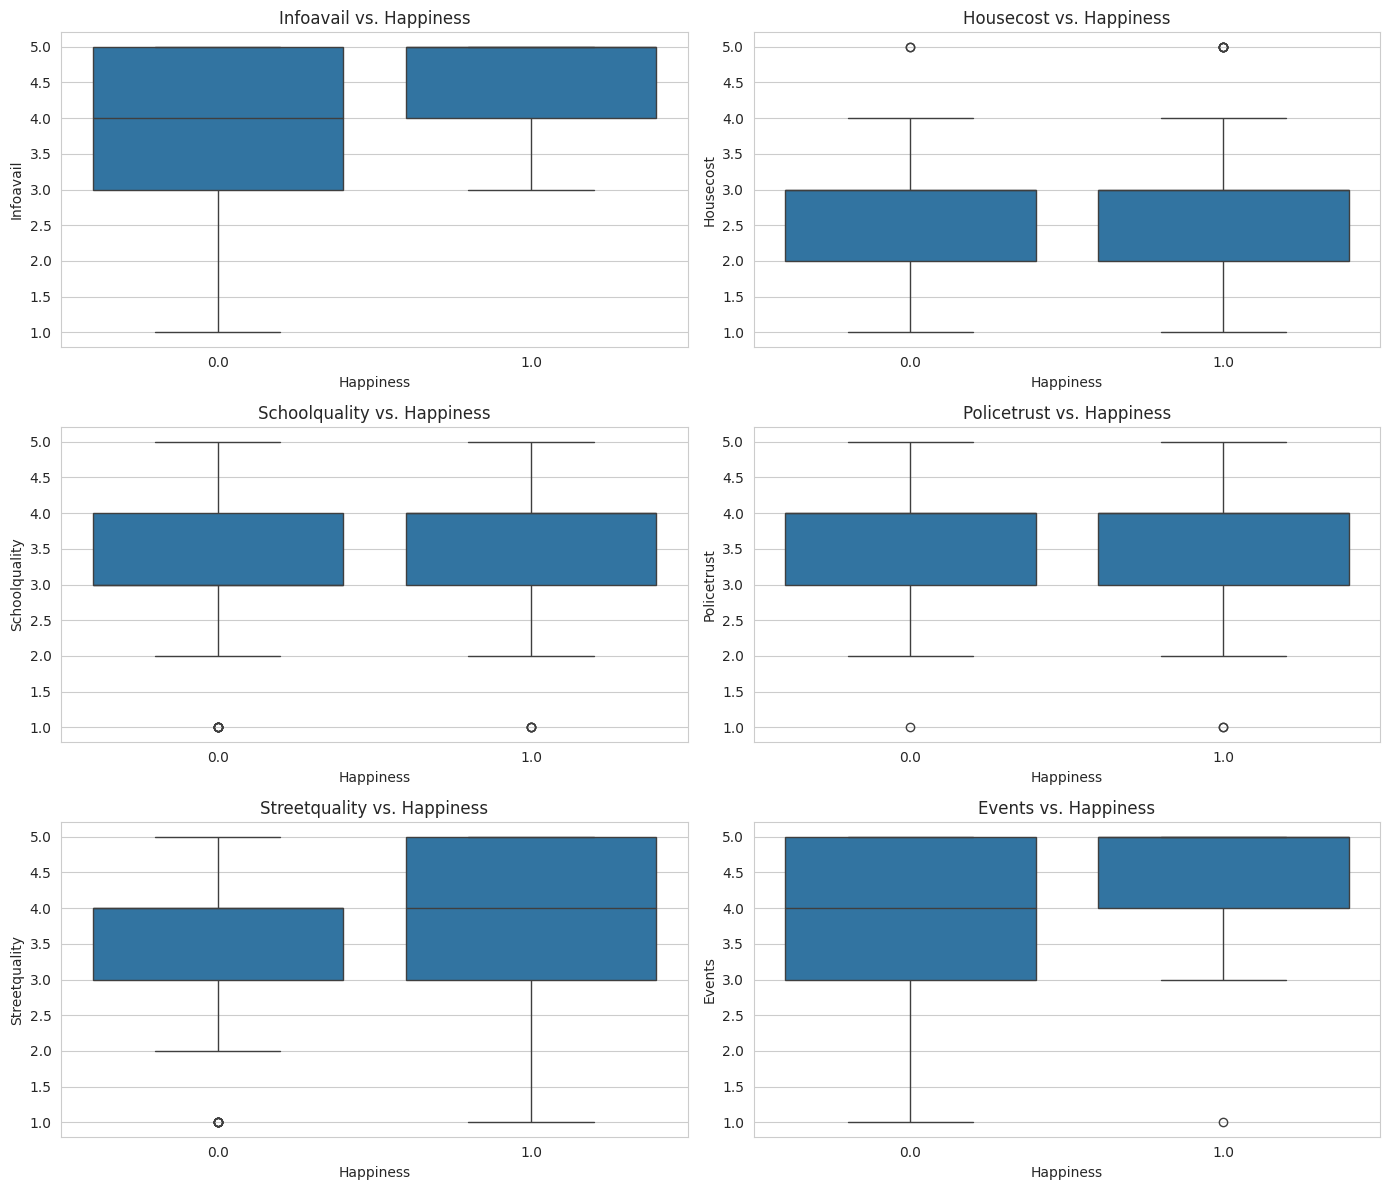

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Tentukan fungsi untuk membuat plot box untuk setiap fitur terhadap happiness
def plot_feature_distribution(dataframe, feature, ax):
    sns.boxplot(x='happy', y=feature, data=dataframe, ax=ax)
    ax.set_title(f'{feature.capitalize()} vs. Happiness')
    ax.set_xlabel('Happiness')
    ax.set_ylabel(feature.capitalize())

# Plotting
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
features = ['infoavail', 'housecost', 'schoolquality', 'policetrust', 'streetquality', 'events']

for ax, feature in zip(axes.flatten(), features):
    plot_feature_distribution(data, feature, ax)

plt.tight_layout()
plt.show()

Distribusi data menunjukkan bahwa meningkatkan ketersediaan informasi tentang layanan kota, memelihara jalan dan trotoar, dan ketersediaan acara dapat berdampak pada kebahagiaan warga. Sedangkan, memastikan sekolah berkualitas tinggi, kepercayaan pada polisi setempat, dan perumahan yang terjangkau juga berkontribusi terhadap kebahagiaan secara keseluruhan dan tidak boleh diabaikan.

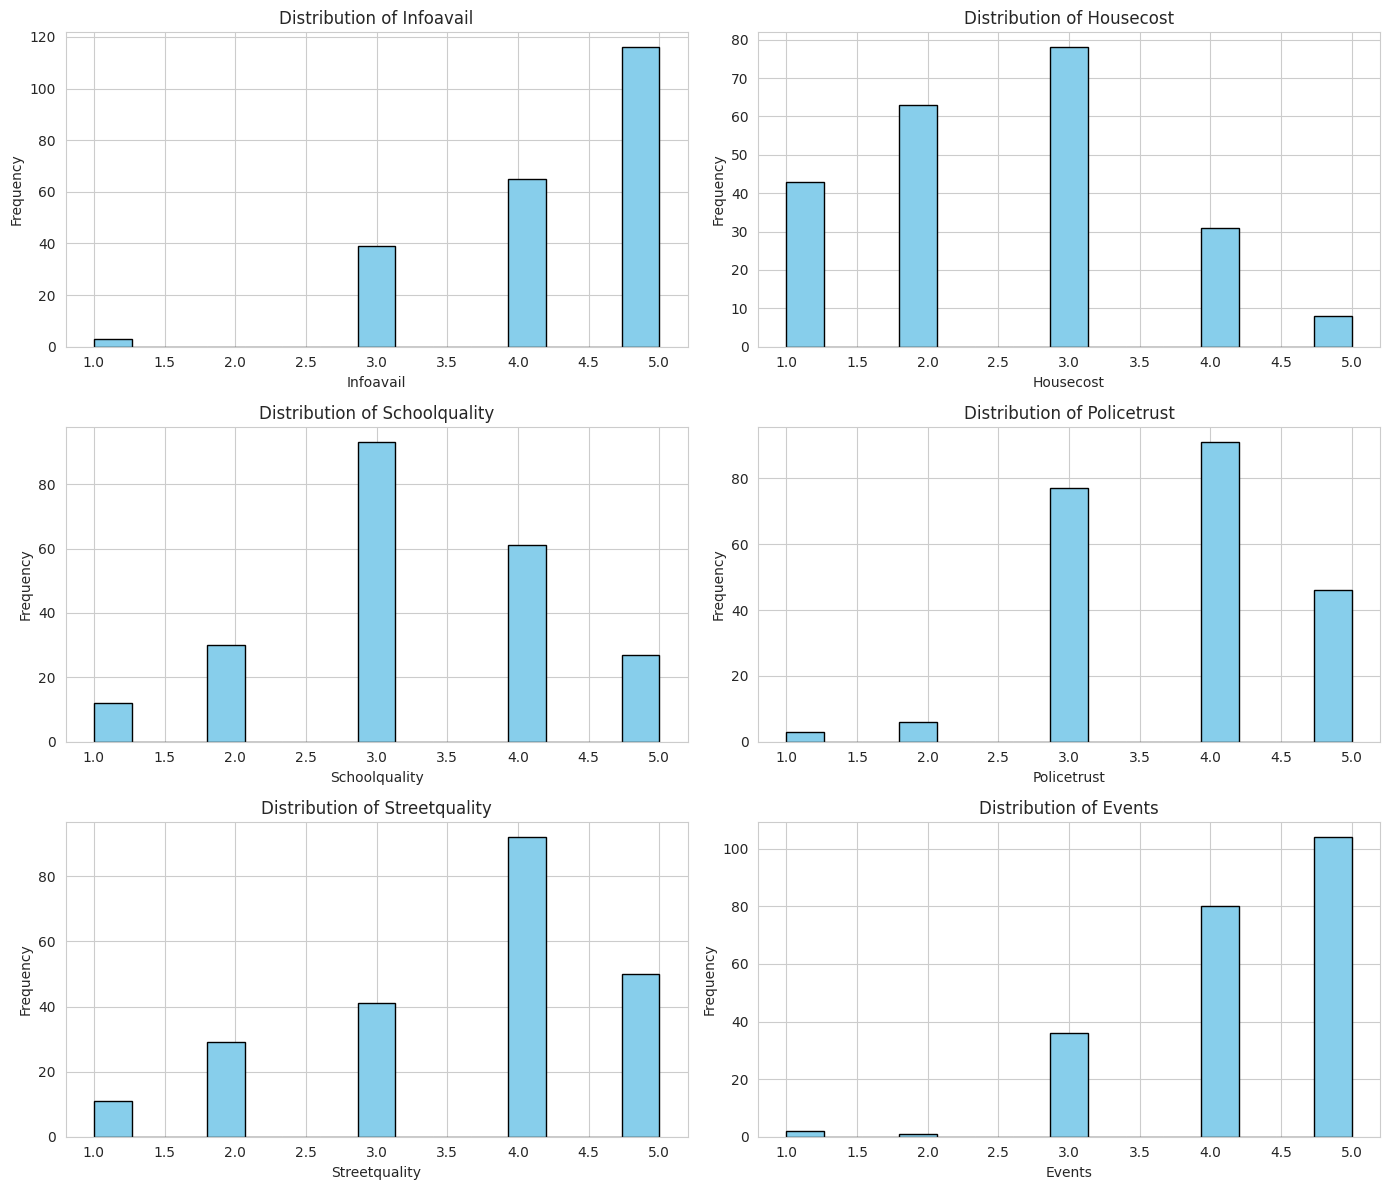

In [ ]:
# Histogram untuk semua fitur
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
features = ['infoavail', 'housecost', 'schoolquality', 'policetrust', 'streetquality', 'events']

for ax, feature in zip(axes.flatten(), features):
    data[feature].hist(ax=ax, bins=15, color='skyblue', edgecolor='black')
    ax.set_title(f'Distribution of {feature.capitalize()}')
    ax.set_xlabel(feature.capitalize())
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

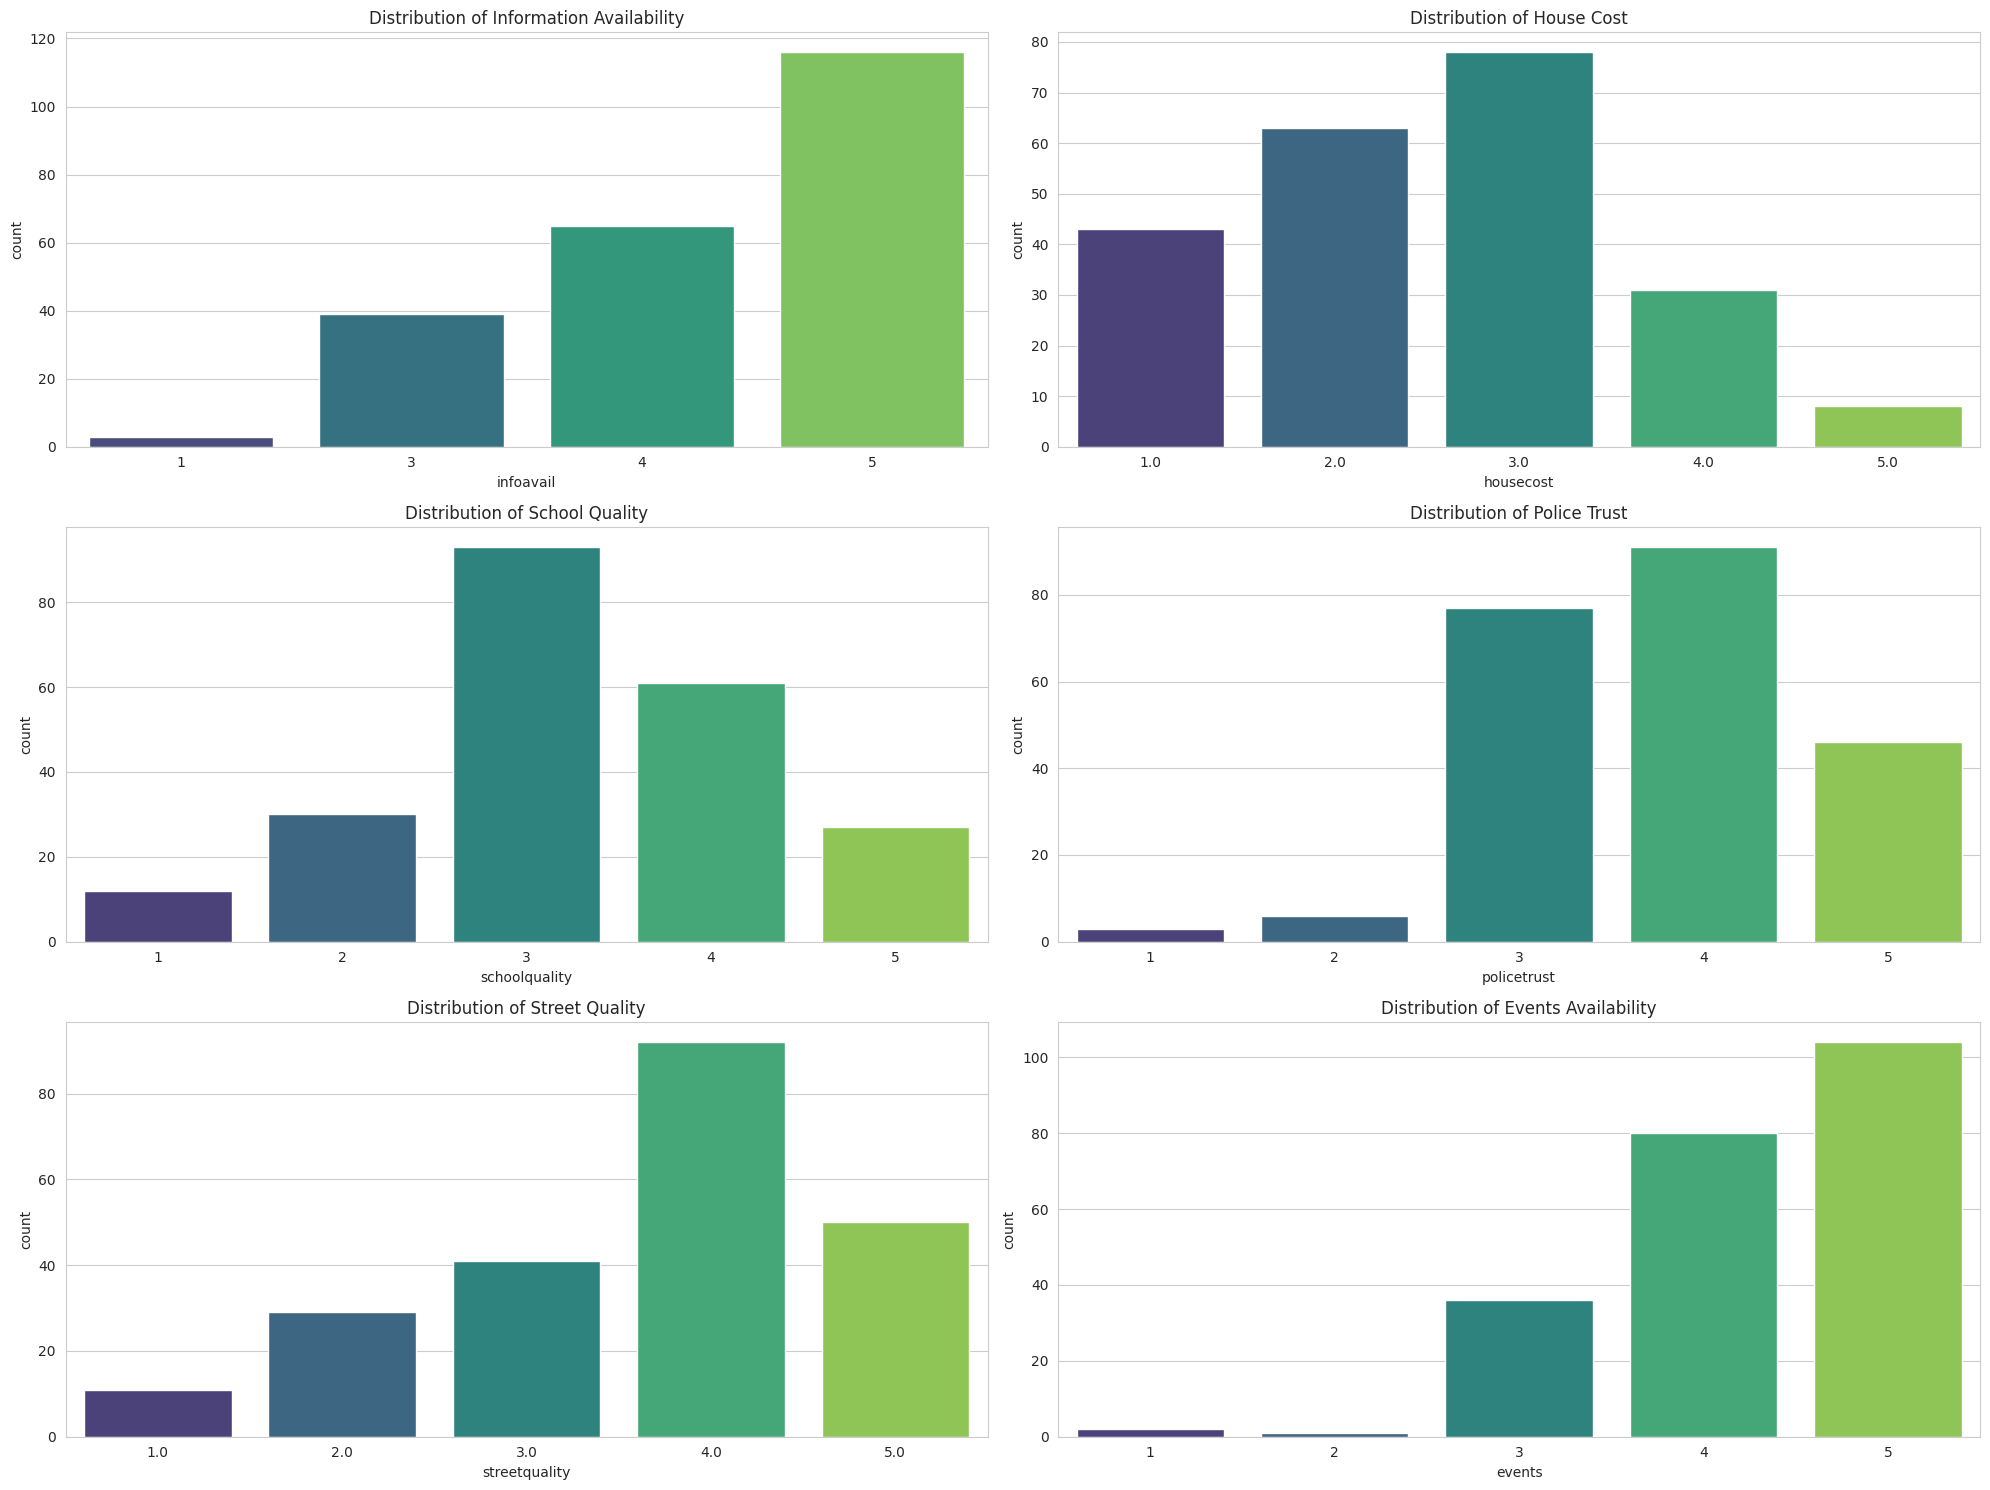

In [ ]:
# Plotting distributions of features with the updated dataset
plt.figure(figsize=(20, 15))

# Subplot 1: Distribution of 'infoavail'
plt.subplot(3, 2, 1)
sns.countplot(x='infoavail', data=data, palette='viridis')
plt.title('Distribution of Information Availability')

# Subplot 2: Distribution of 'housecost'
plt.subplot(3, 2, 2)
sns.countplot(x='housecost', data=data, palette='viridis')
plt.title('Distribution of House Cost')

# Subplot 3: Distribution of 'schoolquality'
plt.subplot(3, 2, 3)
sns.countplot(x='schoolquality', data=data, palette='viridis')
plt.title('Distribution of School Quality')

# Subplot 4: Distribution of 'policetrust'
plt.subplot(3, 2, 4)
sns.countplot(x='policetrust', data=data, palette='viridis')
plt.title('Distribution of Police Trust')

# Subplot 5: Distribution of 'streetquality'
plt.subplot(3, 2, 5)
sns.countplot(x='streetquality', data=data, palette='viridis')
plt.title('Distribution of Street Quality')

# Subplot 6: Distribution of 'events'
plt.subplot(3, 2, 6)
sns.countplot(x='events', data=data, palette='viridis')
plt.title('Distribution of Events Availability')

plt.tight_layout()
plt.show()

Berdasarkan hasil visualisasi tersebut, dapat dianalisis bahwa:
- Infoavail: Sebagian besar responden menilai ketersediaan informasi mengenai layanan kota sangat tinggi, yang artinya infoavail dikota tersebut memiliki kinerja yang baik.
- Housecost: Terdapat distribusi yang agak seimbang di berbagai nilai, dengan sedikit kecenderungan ke arah biaya yang lebih tinggi.
- Schoolquality: Penilaiannya cukup positif dengan sebagian besar penilaian berada pada skala menengah ke atas.
- Policetrust: Walaupun terdapat variabilitas, terdapat tingkat kepercayaan yang tinggi pada polisi setempat di kalangan responden.
- Streetquality: Penilaiannya bernilai positif, dengan banyak responden yang mneyatakan puas.
- Events: Hal ini juga dinilai positif oleh sejumlah besar responden, yang menunjukkan ketersediaan acara sosial dan komunitas yang baik.

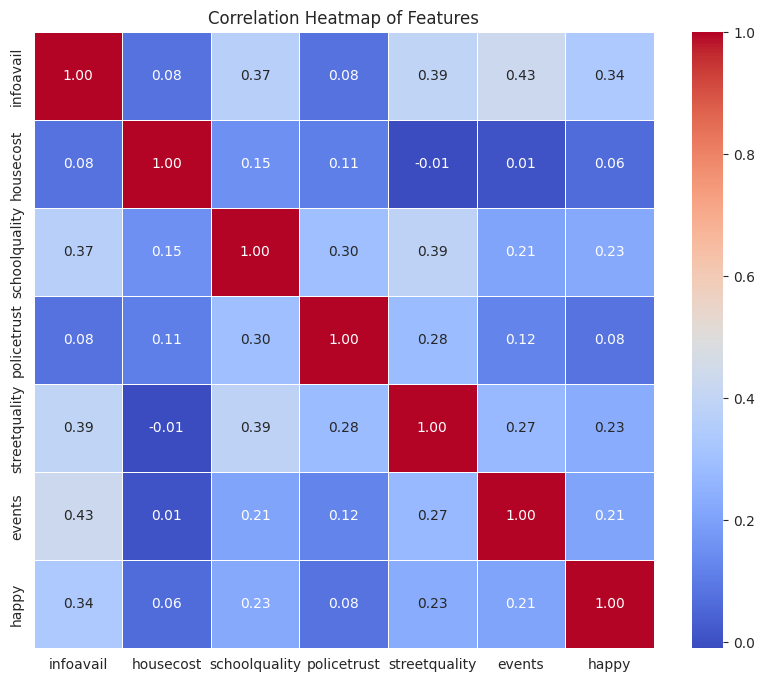

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Features')
plt.show()

# Implementation of KNN

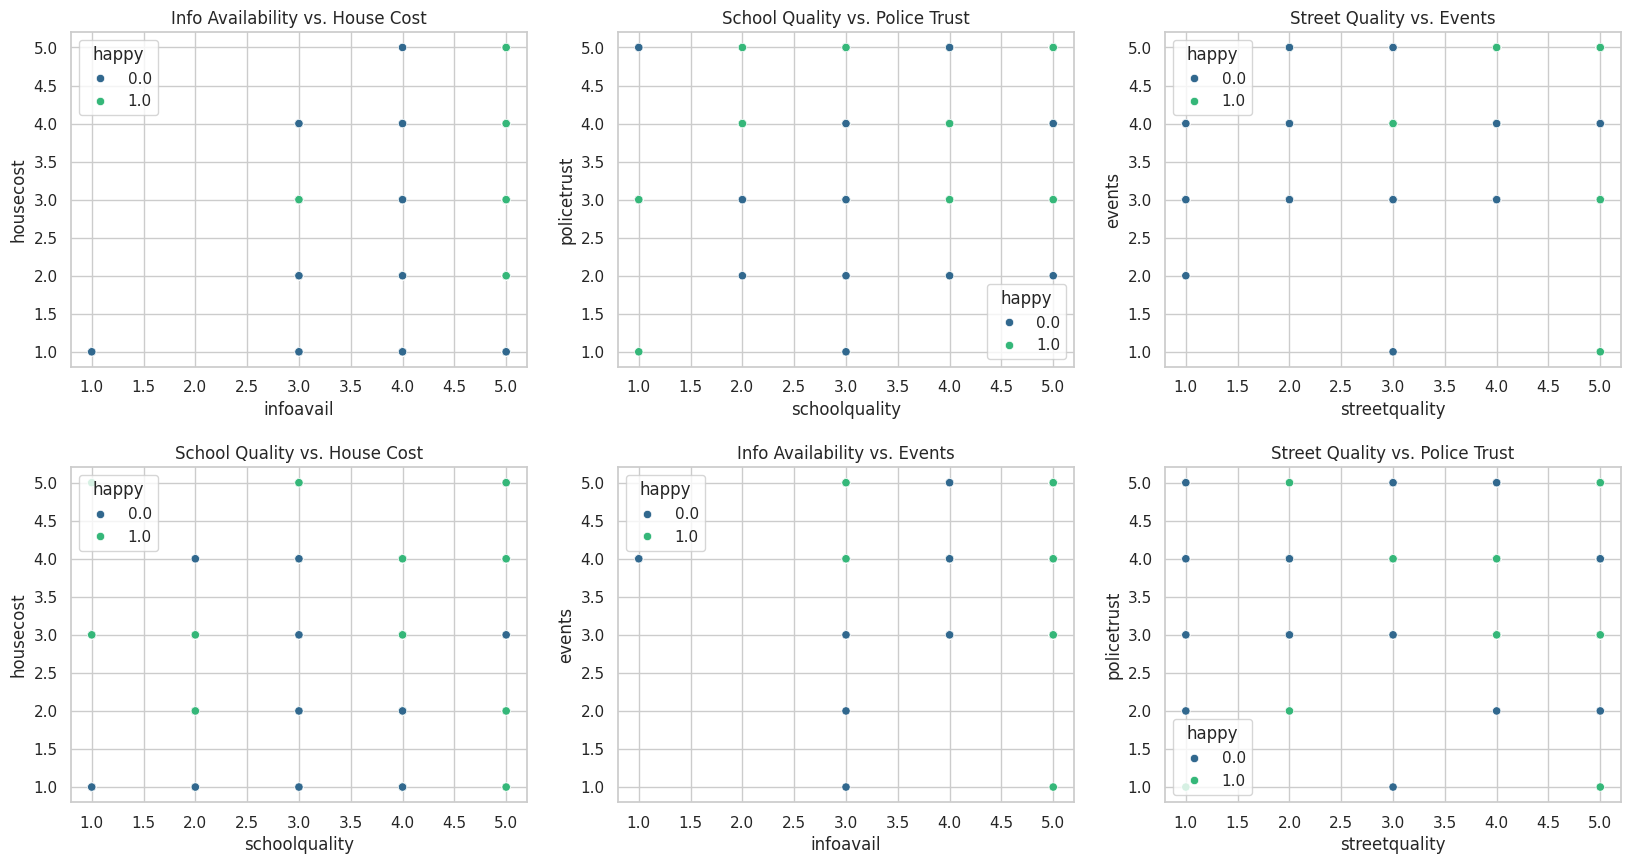

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style of seaborn
sns.set(style="whitegrid")

# Create a subplot of 2x3 graph space for visualizing the features relationships
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.subplots_adjust(hspace=0.3, wspace=0.2)

# Plotting different feature relationships
# infoavail vs. housecost
sns.scatterplot(ax=axes[0, 0], x='infoavail', y='housecost', hue='happy', data=data, palette='viridis')
axes[0, 0].set_title('Info Availability vs. House Cost')

# schoolquality vs. policetrust
sns.scatterplot(ax=axes[0, 1], x='schoolquality', y='policetrust', hue='happy', data=data, palette='viridis')
axes[0, 1].set_title('School Quality vs. Police Trust')

# streetquality vs. events
sns.scatterplot(ax=axes[0, 2], x='streetquality', y='events', hue='happy', data=data, palette='viridis')
axes[0, 2].set_title('Street Quality vs. Events')

# schoolquality vs. housecost
sns.scatterplot(ax=axes[1, 0], x='schoolquality', y='housecost', hue='happy', data=data, palette='viridis')
axes[1, 0].set_title('School Quality vs. House Cost')

# infoavail vs. events
sns.scatterplot(ax=axes[1, 1], x='infoavail', y='events', hue='happy', data=data, palette='viridis')
axes[1, 1].set_title('Info Availability vs. Events')

# streetquality vs. policetrust
sns.scatterplot(ax=axes[1, 2], x='streetquality', y='policetrust', hue='happy', data=data, palette='viridis')
axes[1, 2].set_title('Street Quality vs. Police Trust')

plt.show()


## Data Partition

In [ ]:
from sklearn.model_selection import train_test_split

# Define the features and the target
X = data.drop('happy', axis=1)  # Features
y = data['happy']  # Target

# Splitting the data into training and testing sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2)

# Checking the shapes of the splits
(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

((156, 6), (67, 6), (156,), (67,))

In [ ]:
from sklearn.model_selection import train_test_split

#Get the entire features in the happines dataset
feature_data = data.iloc[:, :-1]
label_data = data["happy"]
# Splitting the data into training and testing sets (70% train, 30% test)
x_train, x_test, y_train, y_test = train_test_split(
    feature_data, label_data, test_size=0.3, random_state=2)

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

x_test  # Output happines_check

(156, 6)
(67, 6)
(156,)
(67,)


,infoavail,housecost,schoolquality,policetrust,streetquality,events
179,4,3.0,3,3,3.0,5
139,5,2.0,3,4,2.0,5
175,4,3.0,4,4,2.0,4
47,3,1.0,2,4,3.0,5
29,3,3.0,1,3,3.0,4
...,...,...,...,...,...,...
154,5,4.0,4,4,4.0,5
96,5,4.0,2,4,3.0,5
132,3,4.0,4,5,1.0,3
11,4,4.0,3,4,4.0,4


## Hyperparameter Tuning:

In [ ]:
import numpy as np
from sklearn import neighbors


train_score = {}
test_score = {}
n_neighbors = np.arange(2, 10, 1)
for k_num in n_neighbors:
    knn = neighbors.KNeighborsClassifier(n_neighbors=k_num)
    knn.fit(X_train, y_train)
    train_score[k_num]=knn.score(X_train, y_train)
    test_score[k_num]=knn.score(X_test, y_test)

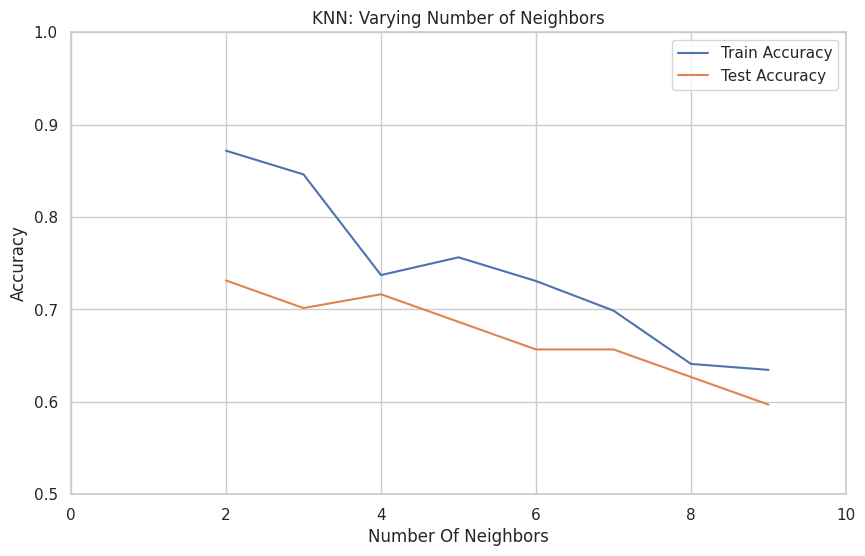

In [ ]:
# Plotting the Train Score and Test Score
plt.figure(figsize=(10, 6))
plt.plot(list(train_score.keys()), list(train_score.values()), label='Train Accuracy')
plt.plot(list(test_score.keys()), list(test_score.values()), label='Test Accuracy')
plt.xlabel('Number Of Neighbors')
plt.ylabel('Accuracy')
plt.title('KNN: Varying Number of Neighbors')
plt.legend()
plt.xlim(0, 10)
plt.ylim(0.50, 1)
plt.grid(True)
plt.show()

In [ ]:
for key, value in test_score.items():
    if value==max(test_score.values()):
        print(f'The Best K is : {key}')

The Best K is : 2


In [ ]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier

kf=KFold(n_splits=5,shuffle=True,random_state=42)
parameter={'n_neighbors': np.arange(2, 10, 1)}
knn=KNeighborsClassifier()
knn_cv=GridSearchCV(knn, param_grid=parameter, cv=kf, verbose=1)
knn_cv.fit(X_train, y_train)
print(knn_cv.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
{'n_neighbors': 3}


## Model Implementation :

In [ ]:
from sklearn import neighbors
import sklearn

def sklearn_classify(train_data, label_data, test_data):
    knn = neighbors.KNeighborsClassifier(n_neighbors=3)
    # Train
    knn.fit(train_data, label_data)
    # Predict
    predict_label = knn.predict(test_data)
    # Return
    return predict_label

In [ ]:
y_predict=sklearn_classify(X_train, y_train, X_test)
y_predict

array([0., 0., 0., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 0., 1., 0., 1., 0., 1., 0., 1., 0., 0., 1., 0.,
       0., 0., 0., 1., 1., 1., 1., 1., 0., 1., 1., 1., 0., 1., 0., 0., 1.,
       0., 0., 0., 1., 0., 1., 0., 1., 1., 1., 0., 1., 0., 0., 1., 1.])

## Accuracy :

In [ ]:
def get_accuracy(test_labels, pred_labels):
    correct = np.sum(test_labels == pred_labels) # Calculate the number of correct predictions
    n = len(test_labels) # Total number of test data
    accur=correct/n
    return accur

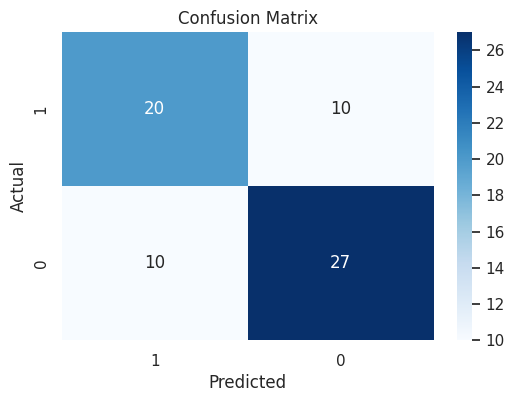

In [ ]:
import seaborn as sns
# import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_predict)

# Plot heatmap
plt.figure(figsize=(6, 4))
sns.set(font_scale=1)  # Atur ukuran font
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=['1', '0'], yticklabels=['1', '0'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_test, y_predict))

[[20 10]
 [10 27]]


In [ ]:
# Classification Report
from sklearn.metrics import classification_report

cls_report = classification_report(y_test, y_predict)

print(f'Classification Report:\n{cls_report}')

Classification Report:
              precision    recall  f1-score   support

         0.0       0.67      0.67      0.67        30
         1.0       0.73      0.73      0.73        37

    accuracy                           0.70        67
   macro avg       0.70      0.70      0.70        67
weighted avg       0.70      0.70      0.70        67



Berdasarkan nilai ketepatan prediksi diatas maka dapat diketahui bahwa 0.70 merupakan nilai rata-rata yang cukup besar dari perhitungan yang lainnya maka hal itu menandakan ketepatan prediksi yang paling baik yaitu pada bagian precision dengan nilai 0.70 .

In [ ]:
from sklearn.metrics import accuracy_score

accuracy= accuracy_score(y_test, y_predict)
accuracy

0.7014925373134329

# K-Means

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

X = data.values[:,1:]
X = np.nan_to_num(X)

customer_dataset = StandardScaler().fit_transform(X)
customer_dataset

array([[ 0.43083638, -0.26916422,  0.27369179, -1.46762263, -0.33268707,
        -1.06968723],
       [-0.51109021, -0.26916422,  1.44740852,  0.33061828, -1.56917401,
        -1.06968723],
       [ 0.43083638, -0.26916422, -0.90002493, -0.56850217,  0.90379987,
         0.9348527 ],
       ...,
       [ 0.43083638, -0.26916422, -0.90002493, -0.56850217,  0.90379987,
        -1.06968723],
       [ 2.31468954, -0.26916422,  1.44740852,  1.22973874,  0.90379987,
         0.9348527 ],
       [ 1.37276296,  1.69882335,  1.44740852,  1.22973874,  0.90379987,
         0.9348527 ]])

# MODELING :

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
scores = []
for i in range(2, 8):
    km = KMeans(n_clusters = i, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
    km.fit(X)
    wcss.append(km.inertia_)

    labels = km.labels_
    silhouette_avg = silhouette_score(X, labels)
    scores.append(silhouette_avg)
    print('wcss score for n_cluster = ' + str(i) + ' is ' + str(wcss))
    print('silhoutte score for n_clusters = ' + str(i) + ' is ' + str(silhouette_avg) + '\n')

wcss score for n_cluster = 2 is [855.1460437710435]
silhoutte score for n_clusters = 2 is 0.22544537986465552

wcss score for n_cluster = 3 is [855.1460437710435, 723.0856998949785]
silhoutte score for n_clusters = 3 is 0.19377176827049922

wcss score for n_cluster = 4 is [855.1460437710435, 723.0856998949785, 654.6288863473537]
silhoutte score for n_clusters = 4 is 0.17480605610312408

wcss score for n_cluster = 5 is [855.1460437710435, 723.0856998949785, 654.6288863473537, 585.0277426148825]
silhoutte score for n_clusters = 5 is 0.19354632042983116

wcss score for n_cluster = 6 is [855.1460437710435, 723.0856998949785, 654.6288863473537, 585.0277426148825, 540.0186198990681]
silhoutte score for n_clusters = 6 is 0.20395198949555315

wcss score for n_cluster = 7 is [855.1460437710435, 723.0856998949785, 654.6288863473537, 585.0277426148825, 540.0186198990681, 499.33676135894177]
silhoutte score for n_clusters = 7 is 0.20289085302715607



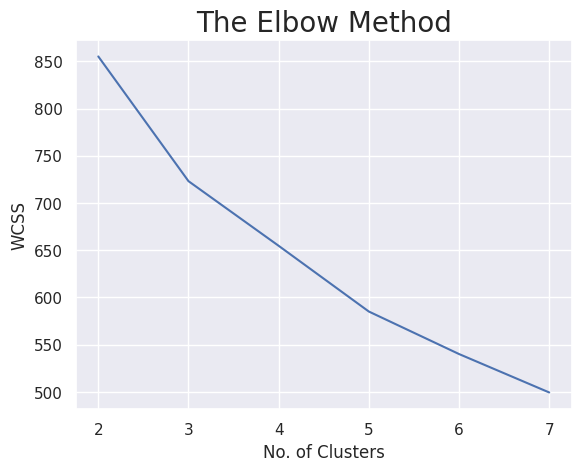

In [ ]:
import matplotlib.pyplot as plt

# Visualizing Elbow Method
plt.plot(range(2, 8), wcss)
plt.title('The Elbow Method', fontsize = 20)
plt.xlabel('No. of Clusters')
plt.ylabel('WCSS')
plt.show()

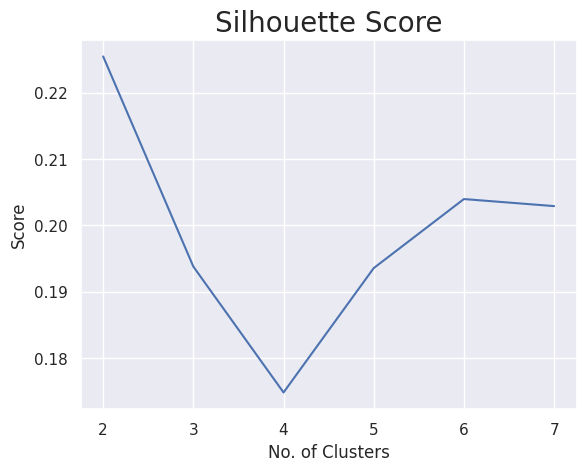

In [ ]:
# Visualizing Silhouette Score
plt.plot(range(2, 8), scores)
plt.title('Silhouette Score', fontsize = 20)
plt.xlabel('No. of Clusters')
plt.ylabel('Score')
plt.show()

In [ ]:
# Model Build
kmeansmodel = KMeans(n_clusters = 2, init = 'k-means++', max_iter = 300, n_init = 10, random_state = 0)
y_kmeans = kmeansmodel.fit_predict(X)

In [ ]:
data["Cluster_Label"] = labels
data.head()

,infoavail,housecost,schoolquality,policetrust,streetquality,events,happy,Cluster_Label
0,3,3.0,3,4,2.0,4,0.0,5
1,3,2.0,3,5,4.0,3,0.0,0
2,5,3.0,3,3,3.0,5,1.0,1
3,5,4.0,3,3,3.0,5,0.0,1
4,5,4.0,3,3,3.0,5,0.0,1


In [ ]:
data.groupby('Cluster_Label').mean()

,infoavail,housecost,schoolquality,policetrust,streetquality,events,happy
Cluster_Label,,,,,,,
0,4.179487,2.820513,2.717949,4.076923,3.923077,3.743590,0.487179
1,4.642857,3.035714,3.071429,3.035714,2.607143,4.785714,0.428571
2,4.693878,1.857143,4.081633,3.877551,4.428571,4.755102,0.795918
3,3.052632,2.157895,1.736842,2.684211,2.210526,3.210526,0.263158
4,4.636364,3.727273,4.363636,4.424242,4.606061,4.696970,0.666667
5,3.800000,3.450000,3.550000,4.100000,1.900000,3.600000,0.400000
6,4.285714,1.371429,2.571429,3.628571,3.857143,4.314286,0.400000


In [ ]:
import plotly.graph_objects as go

df = pd.DataFrame(data)

# Membuat plot
PLOT = go.Figure()
for C in df.Cluster_Label.unique():
    PLOT.add_trace(go.Scatter3d(
        x=df[df.Cluster_Label == C]['streetquality'],
        y=df[df.Cluster_Label == C]['housecost'],
        z=df[df.Cluster_Label == C]['policetrust'],
        mode='markers',
        marker=dict(size=6, line=dict(width=1)),
        name=str(C)
    ))

PLOT.update_traces(hovertemplate='streetquality	: %{x} <br>housecost: %{y} <br>policetrust: %{z}')

PLOT.update_layout(
    width=800, height=800, autosize=True, showlegend=True,
    scene=dict(
        xaxis=dict(title='streetquality	', titlefont_color='black'),
        yaxis=dict(title='housecost', titlefont_color='black'),
        zaxis=dict(title='policetrust', titlefont_color='black')
    ),
    font=dict(family="Gilroy", color='black', size=12)
)

PLOT.show()